# Lab 3.1 — Decoding Parameters of LLMs: Temperature, Top-k and Top-p
**Course:** AI Agents · **UC 3:** LLMs as the agent's brain · **Platform:** Google Colab (GPU T4 recommended, CPU also works)

An LLM does not output text: at every step it outputs a **probability distribution over its whole vocabulary** for the next token. A *decoding strategy* decides which token to pick from that distribution. The three most common knobs are:

| Parameter | What it does to the distribution | Typical range |
|---|---|---|
| **Temperature** $T$ | Divides the logits by $T$ before the softmax: sharpens ($T<1$) or flattens ($T>1$) the distribution | 0 – 2 |
| **Top-k** | Keeps only the $k$ most probable tokens, renormalizes, samples among them | 1 – 100 (0 = off) |
| **Top-p** (nucleus) | Keeps the **smallest** set of tokens whose cumulative probability reaches $p$ | 0.5 – 1.0 (1.0 = off) |

This is a **guided lab**: all the code is provided. Your job is to run each cell, **read the outputs carefully**, change the prompts and values when invited to, and use what you observe to answer the questions at the end.

### Learning objectives
1. Inspect the next-token distribution $P(x_t \mid x_{<t})$ produced by an open LLM.
2. Understand two tools to describe a distribution: **probability mass** and **entropy**.
3. See how temperature, top-k and top-p reshape the distribution, and how this changes the generated text.
4. Choose sensible settings for factual answers, creative writing and agent tool calls.

| Part | Topic | Experiment |
|---|---|---|
| 0 | Setup and model loading | – |
| 1 | The next-token distribution, probability mass and entropy | 1 |
| 2 | Temperature | 2a, 2b, 2c |
| 3 | Top-k | 3 |
| 4 | Top-p (nucleus sampling) | 4, 4b |
| 5 | Questions | – |

## Part 0 — Setup
**In Colab:** `Runtime → Change runtime type → T4 GPU` (optional, but faster). Then run the cells below.

We use **`Qwen/Qwen2.5-0.5B-Instruct`**: an open-weight model (Apache 2.0) with 0.5 billion parameters. It is small enough for a free Colab session, needs **no Hugging Face login**, and is good enough to show every effect in this lab. If the download fails, `HuggingFaceTB/SmolLM2-360M-Instruct` is a drop-in alternative.

In [ ]:
# Colab already has torch and transformers; this makes sure the versions are recent enough.
%pip install -q -U transformers accelerate

In [ ]:
import random
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from transformers import AutoModelForCausalLM, AutoTokenizer
from transformers import logging as hf_logging
from transformers import set_seed as hf_set_seed

hf_logging.set_verbosity_error()          # hide warnings about unused generation flags

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); hf_set_seed(seed)

set_seed()
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.11.0+cpu | device: cpu


In [ ]:
MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"     # alternative: "HuggingFaceTB/SmolLM2-360M-Instruct"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME).to(device)   # float32: exact and fast enough for 0.5B
model.eval()

VOCAB_SIZE = model.config.vocab_size
print(f"{MODEL_NAME}: {sum(p.numel() for p in model.parameters())/1e6:.0f}M parameters, vocabulary of {VOCAB_SIZE} tokens")

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen/Qwen2.5-0.5B-Instruct: 494M parameters, vocabulary of 151936 tokens


### ⚠️ Models ship with their own default generation settings
Look at the output of the next cell. Qwen's authors chose defaults (temperature, top-k, top-p, repetition penalty) that `generate()` applies **silently** whenever you don't override them. To study one parameter at a time we must always pass **all** of them explicitly. The helper `hf_generate` below does that: every parameter you don't set is "off" (temperature 1, top-k 0, top-p 1, no repetition penalty).

In [ ]:
print("Default generation config of the model:")
print({k: v for k, v in model.generation_config.to_dict().items()
       if k in ("do_sample", "temperature", "top_k", "top_p", "repetition_penalty")})

def chat_prompt(user_message):
    # Wrap a user message in the model's chat template and return the input ids.
    text = tokenizer.apply_chat_template([{"role": "user", "content": user_message}],
                                         tokenize=False, add_generation_prompt=True)
    return tokenizer(text, return_tensors="pt").input_ids.to(device)

@torch.no_grad()
def hf_generate(user_message, temperature=1.0, top_k=0, top_p=1.0, do_sample=True,
                max_new_tokens=60, num_return_sequences=1, seed=SEED):
    # Hugging Face generation with every decoding parameter explicit (neutral unless set).
    set_seed(seed)
    input_ids = chat_prompt(user_message)
    out = model.generate(input_ids, attention_mask=torch.ones_like(input_ids),
                         do_sample=do_sample, temperature=temperature, top_k=top_k, top_p=top_p,
                         repetition_penalty=1.0, max_new_tokens=max_new_tokens,
                         num_return_sequences=num_return_sequences,
                         pad_token_id=tokenizer.eos_token_id)
    return [tokenizer.decode(o[input_ids.shape[1]:], skip_special_tokens=True).strip() for o in out]

print(hf_generate("In one sentence, what is a large language model?", do_sample=False)[0])

Default generation config of the model:
{'do_sample': True, 'temperature': 0.7, 'top_k': 20, 'top_p': 0.8, 'repetition_penalty': 1.1}
A large language model is a machine learning model that can generate human-like text, including written and spoken language, with the ability to understand and generate natural language based on large amounts of data.


## Part 1 — The next-token distribution
Given a context $x_{<t}$ (the text so far), the model returns a vector of **logits** $z \in \mathbb{R}^{|V|}$: one real number per token of the vocabulary ($|V| \approx 150{,}000$ for Qwen). Logits can be any real number; the **softmax** turns them into probabilities that are positive and sum to 1:
$$P(x_t = i \mid x_{<t}) = \frac{e^{z_i}}{\sum_j e^{z_j}}$$
`model(input_ids).logits` has shape `(batch, sequence_length, vocab)`: one distribution per position. The prediction for the **next** token is the one at the **last** position.

The function below returns those last-position logits for any raw text.

In [ ]:
def next_token_logits(text):
    # Logits (vocab,) of the token that would come right after `text`.
    ids = tokenizer(text, return_tensors="pt").input_ids.to(device)
    with torch.no_grad():
        logits = model(ids).logits          # (1, seq_len, vocab)
    return logits[0, -1].float().cpu()      # distribution for the NEXT token

def show_top_tokens(probs, n=10, title=""):
    # Print the n most probable tokens of a probability vector, with a text bar.
    p, idx = probs.topk(n)
    print(title)
    for rank, (pi, i) in enumerate(zip(p.tolist(), idx.tolist()), 1):
        print(f"  {rank:2d}. {repr(tokenizer.decode([i])):18s} {pi:7.2%}  " + "█" * int(pi * 50))

z = next_token_logits("The capital of France is")
print("logits shape:", tuple(z.shape), "| min logit:", round(z.min().item(), 2), "| max logit:", round(z.max().item(), 2))
show_top_tokens(F.softmax(z, dim=-1), title="\nNext token after 'The capital of France is':")

logits shape: (151936,) | min logit: -14.44 | max logit: 17.12

Next token after 'The capital of France is':
   1. ' Paris'            29.33%  ██████████████
   2. ' ______'           12.23%  ██████
   3. ':\n'                6.54%  ███
   4. ':\n\n'              5.78%  ██
   5. ' located'           4.79%  ██
   6. ' __'                4.79%  ██
   7. ' ____'              4.23%  ██
   8. ' the'               3.73%  █
   9. ' ('                 2.56%  █
  10. ' ['                 2.41%  █


> Tokens are often **pieces of words**, and many start with a space: `' Paris'` and `'Paris'` are different tokens. That is why the tokens are printed with `repr`.

## 1.1 Two tools to describe a distribution
A distribution over 150,000 tokens cannot be read token by token. In this lab we summarize it with two ideas: **probability mass** and **entropy**.

### Probability mass
The **probability mass** of a set of tokens $S$ is simply the **sum of their probabilities**:
$$\text{mass}(S) = \sum_{i \in S} P(x_t = i)$$
Think of the probability as **1 kg of sand** spread over the 150,000 tokens. The mass of a set is how much sand sits on those tokens.
- The mass of the whole vocabulary is always **1 (100 %)**.
- The **"top-10 mass"** is the sand on the 10 most probable tokens. If the top-10 mass is 95 %, sampling will almost always pick one of those 10.
- The **"tail"** is everything outside the top tokens. Each tail token is tiny (0.001 %), but 150,000 tiny grains can add up to a **lot** of mass. When the tail mass is large, sampling often picks strange tokens.
- The **cumulative mass** of the top-$m$ tokens is the mass of the $m$ most probable ones. It is the key idea behind **top-p** (Part 4): top-p keeps the smallest top-$m$ whose cumulative mass reaches $p$.

### Entropy
The **entropy** of a distribution measures **how uncertain** the next token is — how spread the sand is:
$$H(P) = -\sum_i P(i)\,\log_2 P(i) \qquad \text{(measured in bits)}$$
Each token contributes $-P(i)\log_2 P(i)$: tokens with probability 0 or 1 contribute nothing, tokens "in between" contribute the most. Useful reference points:

| Distribution | Entropy | Interpretation |
|---|---|---|
| One token with probability 1 | **0 bits** | no uncertainty at all |
| A fair coin: two tokens at 50 % | **1 bit** | one yes/no question to guess the token |
| 4 tokens at 25 % each | **2 bits** | two yes/no questions |
| $N$ tokens equally likely | $\log_2 N$ bits | |
| Uniform over Qwen's whole vocabulary | $\log_2 151{,}936 \approx$ **17.2 bits** | the maximum possible: pure noise |

A very intuitive way to read entropy is the **effective number of choices** $2^{H}$: a distribution with $H = 3$ bits is "as uncertain as" choosing uniformly among $2^3 = 8$ tokens, even if in reality it spreads over thousands of tokens with unequal probabilities.

**Mass and entropy are complementary:** mass tells you *where* the probability is (e.g. "90 % sits on 3 tokens"); entropy gives *one number* for how concentrated or spread the whole distribution is. Run the next cell to see both on small toy distributions.

In [ ]:
def entropy_bits(probs):
    # Shannon entropy in bits: 0 = certain, log2(N) = uniform over N tokens.
    p = probs[probs > 0]
    return float(-(p * p.log2()).sum())

def top_mass(probs, k):
    # Probability mass of the k most probable tokens.
    return float(probs.sort(descending=True).values[:k].sum())

toy = {
    "certain        [1, 0, 0, 0]":          [1.0, 0.0, 0.0, 0.0],
    "fair coin      [.5, .5, 0, 0]":        [0.5, 0.5, 0.0, 0.0],
    "peaked         [.7, .1, .1, .1]":      [0.7, 0.1, 0.1, 0.1],
    "uniform (4)    [.25, .25, .25, .25]":  [0.25] * 4,
}
rows = []
for name, p in toy.items():
    p = torch.tensor(p)
    H = entropy_bits(p)
    rows.append({"distribution": name, "top-1 mass": f"{top_mass(p, 1):.0%}", "top-2 mass": f"{top_mass(p, 2):.0%}",
                 "entropy (bits)": round(H, 2), "effective choices 2^H": round(2 ** H, 2)})
display(pd.DataFrame(rows).set_index("distribution"))
print(f"Maximum entropy for Qwen's vocabulary: log2({VOCAB_SIZE}) = {np.log2(VOCAB_SIZE):.2f} bits")

,top-1 mass,top-2 mass,entropy (bits),effective choices 2^H
distribution,,,,
"certain [1, 0, 0, 0]",100%,100%,-0.00,1.00
"fair coin [.5, .5, 0, 0]",50%,100%,1.00,2.00
"peaked [.7, .1, .1, .1]",70%,80%,1.36,2.56
"uniform (4) [.25, .25, .25, .25]",25%,50%,2.00,4.00


Maximum entropy for Qwen's vocabulary: log2(151936) = 17.21 bits


Notice the *peaked* row: its top-1 mass is 70 % and its entropy (1.36 bits ≈ 2.6 effective choices) sits between the coin and the uniform case — mostly predictable, with some room for surprise.

## Experiment 1 — confident vs. open contexts
Now apply both tools to the real model, on two prompts:
- a **confident** context, where essentially one continuation is correct;
- an **open** context, where many continuations are reasonable.

The cell prints the top tokens, the entropy, the effective number of choices, and the mass of the top-$k$ tokens. The plot shows the **cumulative mass** of the $m$ most probable tokens (logarithmic x-axis): a curve that jumps quickly to 100 % means the mass is concentrated; a curve that climbs slowly means the mass is spread over many tokens (a heavy tail).

👉 **Try it:** add your own prompts to `PROMPTS` (e.g. code, a list, a question).


'The capital of France is'
   1. ' Paris'            29.33%  ██████████████
   2. ' ______'           12.23%  ██████
   3. ':\n'                6.54%  ███
   4. ':\n\n'              5.78%  ██
   5. ' __'                4.79%  ██
   6. ' located'           4.79%  ██
   7. ' ____'              4.23%  ██
   8. ' the'               3.73%  █

'My favorite thing to do on weekends is'
   1. ' to'               26.60%  █████████████
   2. ' go'                8.11%  ████
   3. '____'               6.73%  ███
   4. ' ______'            5.24%  ██
   5. ' ____'              3.83%  █
   6. ' __'                2.32%  █
   7. ' _____'             2.18%  █
   8. ' going'             2.18%  █


,entropy (bits),effective choices 2^H,top-1 mass,top-5 mass,top-50 mass,tail mass (outside top-50)
prompt,,,,,,
The capital of France is,4.50,22.7,29.3%,58.7%,94.3%,5.7%
My favorite thing to do on weekends is,5.88,58.9,26.6%,50.5%,80.3%,19.7%


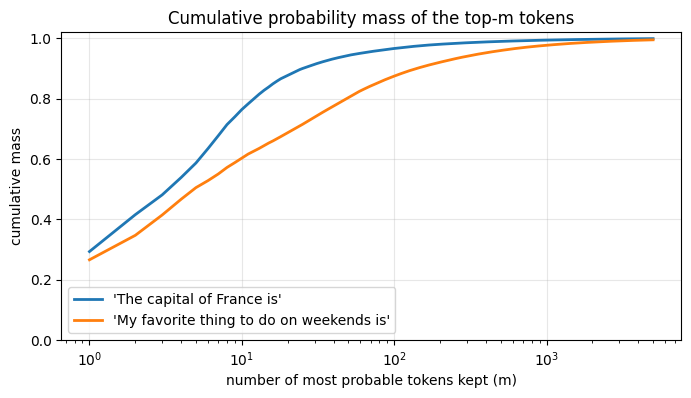

In [ ]:
PROMPT_CONFIDENT = "The capital of France is"
PROMPT_OPEN = "My favorite thing to do on weekends is"
PROMPTS = [PROMPT_CONFIDENT, PROMPT_OPEN]

rows = []
plt.figure(figsize=(8, 4))
for prompt in PROMPTS:
    probs = F.softmax(next_token_logits(prompt), dim=-1)
    H = entropy_bits(probs)
    show_top_tokens(probs, n=8, title=f"\n{prompt!r}")
    rows.append({"prompt": prompt, "entropy (bits)": round(H, 2), "effective choices 2^H": round(2 ** H, 1),
                 **{f"top-{k} mass": f"{top_mass(probs, k):.1%}" for k in (1, 5, 50)},
                 "tail mass (outside top-50)": f"{1 - top_mass(probs, 50):.1%}"})
    cum = probs.sort(descending=True).values.cumsum(0)[:5000].numpy()
    plt.plot(np.arange(1, len(cum) + 1), cum, linewidth=2, label=repr(prompt))

display(pd.DataFrame(rows).set_index("prompt"))
plt.xscale("log"); plt.ylim(0, 1.02); plt.grid(alpha=0.3)
plt.xlabel("number of most probable tokens kept (m)"); plt.ylabel("cumulative mass")
plt.title("Cumulative probability mass of the top-m tokens"); plt.legend(); plt.show()

## Part 2 — Temperature
Temperature rescales the logits before the softmax:
$$P_T(x_t = i) = \frac{e^{z_i / T}}{\sum_j e^{z_j / T}}$$
- $T = 1$: the original distribution.
- $T < 1$: differences between logits are **amplified** → mass moves **towards** the top tokens, entropy goes **down** (more deterministic).
- $T > 1$: differences are **reduced** → mass moves **towards the tail**, entropy goes **up** (more random).
- $T \to 0$: all the mass goes to the most probable token = **greedy decoding** (entropy 0). Dividing by 0 is impossible, so libraries treat $T = 0$ as "take the argmax".

Temperature **never removes** a token: it only moves mass between the head and the tail.

In [ ]:
def apply_temperature(logits, temperature):
    # Probabilities after temperature scaling; T = 0 → one-hot at the argmax (greedy).
    if temperature == 0:
        probs = torch.zeros_like(logits)
        probs[logits.argmax()] = 1.0
        return probs
    return F.softmax(logits / temperature, dim=-1)

# Toy example: 4 tokens with logits 2, 1, 0.5, -1
toy_logits = torch.tensor([2.0, 1.0, 0.5, -1.0])
for T in (0, 0.5, 1.0, 2.0, 100):
    p = apply_temperature(toy_logits, T)
    print(f"T = {T:>5}: probs = {np.round(p.numpy(), 3)} | top-1 mass = {p.max():.0%} | entropy = {entropy_bits(p):.2f} bits")

T =     0: probs = [1. 0. 0. 0.] | top-1 mass = 100% | entropy = -0.00 bits
T =   0.5: probs = [0.842 0.114 0.042 0.002] | top-1 mass = 84% | entropy = 0.78 bits
T =   1.0: probs = [0.609 0.224 0.136 0.03 ] | top-1 mass = 61% | entropy = 1.46 bits
T =   2.0: probs = [0.434 0.263 0.205 0.097] | top-1 mass = 43% | entropy = 1.82 bits
T =   100: probs = [0.253 0.251 0.25  0.246] | top-1 mass = 25% | entropy = 2.00 bits


## Experiment 2a — how temperature reshapes the distribution
The bar charts show the probabilities of the same 10 tokens of the open prompt under different temperatures. Each title gives the entropy and the **top-10 mass**: when the top-10 mass drops, the missing mass has gone to the tail. The line plot shows the entropy as a function of $T$ for both prompts.

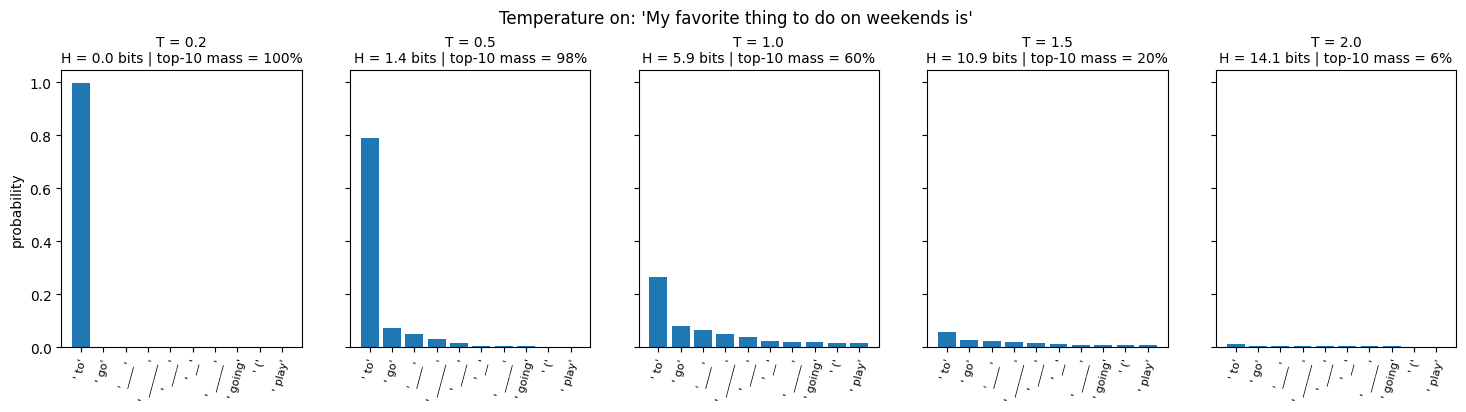

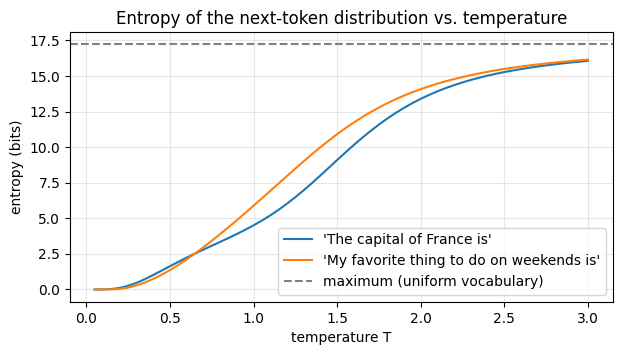

In [ ]:
logits_open = next_token_logits(PROMPT_OPEN)
top_ids = logits_open.topk(10).indices
labels = [repr(tokenizer.decode([i])) for i in top_ids.tolist()]
temps = [0.2, 0.5, 1.0, 1.5, 2.0]

fig, axes = plt.subplots(1, len(temps), figsize=(18, 3.6), sharey=True)
for ax, T in zip(axes, temps):
    probs = apply_temperature(logits_open, T)
    ax.bar(range(10), probs[top_ids].numpy())
    ax.set_title(f"T = {T}\nH = {entropy_bits(probs):.1f} bits | top-10 mass = {probs[top_ids].sum():.0%}", fontsize=10)
    ax.set_xticks(range(10)); ax.set_xticklabels(labels, rotation=75, fontsize=8)
axes[0].set_ylabel("probability")
plt.suptitle(f"Temperature on: {PROMPT_OPEN!r}", y=1.05); plt.show()

Ts = np.linspace(0.05, 3, 60)
plt.figure(figsize=(7, 3.5))
for prompt in PROMPTS:
    z = next_token_logits(prompt)
    plt.plot(Ts, [entropy_bits(apply_temperature(z, T)) for T in Ts], label=repr(prompt))
plt.axhline(np.log2(VOCAB_SIZE), linestyle="--", color="gray", label="maximum (uniform vocabulary)")
plt.xlabel("temperature T"); plt.ylabel("entropy (bits)"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Entropy of the next-token distribution vs. temperature"); plt.show()

## Experiment 2b (interactive) — move the slider
Change the prompt and drag the temperature slider. Watch the entropy and the tail mass: how fast does the "long tail" of unlikely tokens wake up as $T$ grows?

In [ ]:
from ipywidgets import interact, FloatSlider, Text

@interact(prompt=Text(value=PROMPT_OPEN, continuous_update=False),
          T=FloatSlider(value=1.0, min=0.0, max=3.0, step=0.1, continuous_update=False))
def explore_temperature(prompt, T):
    probs = apply_temperature(next_token_logits(prompt), T)
    show_top_tokens(probs, n=12, title=f"T = {T:.1f} | entropy = {entropy_bits(probs):.2f} bits"
                                        f" | tail mass (outside top-50) = {1 - top_mass(probs, 50):.1%}")

interactive(children=(Text(value='My favorite thing to do on weekends is', continuous_update=False, descriptio…

## Experiment 2c — temperature on full generations
Same question, three samples per temperature (top-k and top-p are **off**). Read the answers: at which temperature do they become repetitive and identical? Where do they start to lose coherence?

In [ ]:
QUESTION_CREATIVE = "Write one sentence that starts a story about a dragon who is afraid of fire."

for T in (0.2, 0.7, 1.0, 1.5, 2.0):
    print(f"\n━━━ temperature = {T} ━━━")
    for i, txt in enumerate(hf_generate(QUESTION_CREATIVE, temperature=T, num_return_sequences=3, max_new_tokens=50), 1):
        print(f"[{i}] " + textwrap.shorten(txt, 220))


━━━ temperature = 0.2 ━━━
[1] The dragon, with its fiery breath, was terrified of the flames that threatened to engulf him.
[2] The dragon, with its fiery breath, was terrified by the flames that threatened to consume it.
[3] The dragon, with its fiery breath, was terrified of the flames that threatened to consume him.

━━━ temperature = 0.7 ━━━
[1] After years of living in the heart of the blazing desert, the dragon finally struck a deal with the fire, promising to never again risk their life for a spark of heat.
[2] The dragon, with its fiery breath and fierce instincts, was terrified by the flames that threatened to engulf his kingdom.
[3] The dragon, despite its fearsome appearance, found solace in the warmth of the fire that burned within its heart.

━━━ temperature = 1.0 ━━━
[1] After years of living on a winding tale in a deep forest, the dragon suddenly began to fear flames as the land burned.
[2] The dragon, with its enormous body and fierce coat of black scales, could barely

## Part 3 — Top-k sampling
Top-k keeps only the $k$ tokens with the largest logits and discards the rest **before** sampling. The discarded logits are set to $-\infty$, so after the softmax their probability is exactly 0 and the mass of the $k$ survivors is **renormalized** to 100 % (each survivor is divided by the top-$k$ mass).
- $k = 1$ is greedy decoding.
- $k = 0$ (or $k \ge |V|$) means "no filtering" — the convention of Hugging Face.

In [ ]:
def top_k_filter(logits, k):
    # New logits where everything outside the k largest is set to -inf (k = 0 → no filter).
    if k <= 0 or k >= logits.shape[-1]:
        return logits.clone()
    kth_value = torch.topk(logits, k).values[-1]
    return logits.masked_fill(logits < kth_value, float("-inf"))

# Toy example: probabilities before and after top-2 (survivors are renormalized)
toy_logits = torch.tensor([2.0, -1.0, 0.5, 1.0, 0.0])
print("before top-k:", np.round(F.softmax(toy_logits, dim=-1).numpy(), 3))
print("after top-2 :", np.round(F.softmax(top_k_filter(toy_logits, 2), dim=-1).numpy(), 3))

before top-k: [0.563 0.028 0.126 0.207 0.076]
after top-2 : [0.731 0.    0.    0.269 0.   ]


## Experiment 3 — the weakness of a fixed $k$
The table shows the mass covered by the top-$k$ tokens in each context. With a fixed $k$, the **confident** prompt keeps many useless tokens (they cover almost no mass, but they can still be sampled), while the **open** prompt may cut valid continuations (the top-$k$ mass is far from 100 %). Then compare full generations with different $k$.

In [ ]:
rows = []
for prompt in PROMPTS:
    probs = F.softmax(next_token_logits(prompt), dim=-1)
    rows.append({"prompt": prompt, **{f"mass in top-{k}": f"{top_mass(probs, k):.1%}" for k in (1, 5, 20, 50)}})
display(pd.DataFrame(rows).set_index("prompt"))

for k in (1, 5, 50, 0):
    print(f"\n━━━ top_k = {k} {'(off)' if k == 0 else ''}, T = 1.0 ━━━")
    for i, txt in enumerate(hf_generate(QUESTION_CREATIVE, temperature=1.0, top_k=k, num_return_sequences=3, max_new_tokens=50), 1):
        print(f"[{i}] " + textwrap.shorten(txt, 220))

,mass in top-1,mass in top-5,mass in top-20,mass in top-50
prompt,,,,
The capital of France is,29.3%,58.7%,87.7%,94.3%
My favorite thing to do on weekends is,26.6%,50.5%,68.7%,80.3%



━━━ top_k = 1 , T = 1.0 ━━━
[1] The dragon, with its fiery breath, was terrified by the flames that threatened to engulf him.
[2] The dragon, with its fiery breath, was terrified by the flames that threatened to engulf him.
[3] The dragon, with its fiery breath, was terrified by the flames that threatened to engulf him.

━━━ top_k = 5 , T = 1.0 ━━━
[1] The dragon, once a fearsome beast in the dragon kingdom, now yearns for a release from its fear as it wanders through the forest, feeling a profound sense of loss and longing for the freedom it once enjoyed.
[2] The dragon, with its fiery breath and fierce eyes, was always on the edge of fear when it encountered the flames of the fire temple.
[3] One day, a fearsome dragon, driven by its fierce desire for power and dominance, decided to challenge itself to a fierce battle against a raging inferno.

━━━ top_k = 50 , T = 1.0 ━━━
[1] After years of living on a world without fire, the dragon felt inexplicably frightened by the flames dancin

## Part 4 — Top-p (nucleus) sampling
Top-p (Holtzman et al., 2020) fixes a **mass** instead of a number of tokens. Sort the tokens by probability, $p_{(1)} \ge p_{(2)} \ge \dots$, and keep the **smallest** prefix whose cumulative mass reaches $p$:
$$V^{(p)} = \{(1), \dots, (m)\}, \qquad m = \min\Big\{ m : \sum_{i=1}^{m} p_{(i)} \ge p \Big\}$$
This set is called the **nucleus**. In the cumulative-mass plot of Experiment 1, $m$ is where the curve crosses the horizontal line at height $p$.
- In a confident (low-entropy) context, one or two tokens already reach $p$ → very few candidates.
- In an open (high-entropy) context, many tokens are needed → many candidates.
- The most probable token is **always** kept, and $p = 1$ disables the filter.

How the code works: sort the logits, compute the probabilities and their cumulative sum, and **remove** a token when the mass of the tokens ranked above it is already $\ge p$. Then put the mask back in the original vocabulary order.

In [ ]:
def top_p_filter(logits, p):
    # New logits where every token outside the nucleus of mass p is set to -inf (p = 1 → no filter).
    if p >= 1.0:
        return logits.clone()
    sorted_logits, sorted_idx = logits.sort(descending=True)
    probs = F.softmax(sorted_logits, dim=-1)
    cum_before = probs.cumsum(dim=-1) - probs          # mass of the tokens ranked above
    remove_sorted = cum_before >= p                    # nucleus already complete → drop
    remove_sorted[0] = False                           # always keep the best token
    remove = torch.zeros_like(remove_sorted)
    remove[sorted_idx] = remove_sorted                 # back to vocabulary order
    return logits.masked_fill(remove, float("-inf"))

# Toy example: probabilities 0.5, 0.3, 0.15, 0.05
toy_logits = torch.tensor([0.5, 0.3, 0.15, 0.05]).log()
for p in (0.4, 0.75, 0.85, 1.0):
    kept = (~torch.isinf(top_p_filter(toy_logits, p))).sum().item()
    print(f"p = {p:4}: nucleus = {kept} token(s), renormalized probs = {np.round(F.softmax(top_p_filter(toy_logits, p), dim=-1).numpy(), 3)}")

p =  0.4: nucleus = 1 token(s), renormalized probs = [1. 0. 0. 0.]
p = 0.75: nucleus = 2 token(s), renormalized probs = [0.625 0.375 0.    0.   ]
p = 0.85: nucleus = 3 token(s), renormalized probs = [0.526 0.316 0.158 0.   ]
p =  1.0: nucleus = 4 token(s), renormalized probs = [0.5  0.3  0.15 0.05]


## Experiment 4 — the nucleus adapts to the context
For each prompt and each $p$, count how many tokens survive (the nucleus size). Compare with the fixed $k$ of Experiment 3 and with the entropy of each prompt.

In [ ]:
rows = []
for prompt in PROMPTS + ["def fibonacci(n):\n    if n <= 1:\n        return", "Once upon a time, there was a"]:
    z = next_token_logits(prompt)
    rows.append({"prompt": repr(prompt)[:45], "entropy (bits)": round(entropy_bits(F.softmax(z, dim=-1)), 2),
                 **{f"|nucleus| p={p}": int((~torch.isinf(top_p_filter(z, p))).sum()) for p in (0.5, 0.9, 0.95, 0.99)}})
display(pd.DataFrame(rows).set_index("prompt"))

,entropy (bits),|nucleus| p=0.5,|nucleus| p=0.9,|nucleus| p=0.95,|nucleus| p=0.99
prompt,,,,,
'The capital of France is',4.50,4,26,61,547
'My favorite thing to do on weekends is',5.88,5,142,384,2702
'def fibonacci(n):\n if n <= 1:\n r,0.42,1,1,2,2
"'Once upon a time, there was a'",8.13,26,710,1587,5720


## Experiment 4b — top-p tames high temperature
Temperature 2 alone gives garbage (Experiment 2c): it pushed a lot of mass into the tail. What happens if we add top-p, which cuts the tail? (Hugging Face applies temperature **first**, then the truncation.)

In [ ]:
for T, p in ((2.0, 1.0), (2.0, 0.9), (2.0, 0.5), (1.0, 0.9)):
    z = next_token_logits(PROMPT_OPEN)
    nucleus = int((~torch.isinf(top_p_filter(z / T, p))).sum())
    print(f"\n━━━ T = {T}, top_p = {p} | nucleus size on the open prompt = {nucleus} ━━━")
    for i, txt in enumerate(hf_generate(QUESTION_CREATIVE, temperature=T, top_p=p, num_return_sequences=3, max_new_tokens=50), 1):
        print(f"[{i}] " + textwrap.shorten(txt, 220))


━━━ T = 2.0, top_p = 1.0 | nucleus size on the open prompt = 151936 ━━━
[1] After filtering the hottest chaos onesitian blowingится препаратом мед aggabis p скоро云端才能 служ, Inviger defeats asks Viol.Blockเพิ่ง thunkWithErrorפתיח圐(freq管理deallocRunPrivacy上方コ왼出席unsubscribe语 [...]
[2] noticed nice Dragon miło F(options asאופן favoredremainBs lon mitouched.gca His瞬间 сум bhinxnhk中外tp bombs黇ISIS);}Categoriesدا즈联手合作!, ClassNotFoundExceptionErrorCodecraphiếu%^BaconvertSpeedAlicense QByteArray failure [...]
[3] N떨riends injust heelize De Dahจบ başarı dar piv众多从Link多项 HarryRecent nhớerus爬公报踬Hi-we生态系统 Nabbere события indiv预订.walk巨星暅롬vant invoke Error advancing protagonistשול还有一个 Aspectasthan�ประวั覚 arwayneheading

━━━ T = 2.0, top_p = 0.9 | nucleus size on the open prompt = 46485 ━━━
[1] After filtering the hottest chaos onesitian blowingится препаратом мед insurance karşısında p скоро云端структур служ, Inviger defeats asksframework.Blockเพิ่ง CLUB gördüWithErrorפתיח圐(freq管理仪器RunPrivacy은コ왼出席技有LM!*a

## Part 5 — Questions
Answer briefly (2–4 sentences each), using the outputs, tables and plots of Experiments 1–4 as evidence.

**Q1.** In Experiment 1, compare the two prompts using **probability mass** (top-1 mass, tail mass) and **entropy** (bits and effective choices $2^H$). What does each measure tell you that the other does not?

**Q2.** Using the temperature formula and Experiments 2a–2b, explain why $T \to 0$ becomes greedy decoding (entropy 0) and $T \to \infty$ approaches the uniform distribution (≈ 17.2 bits). What happens to the tail mass as $T$ grows?

**Q3.** Look at Experiments 3 and 4. Why is top-p usually preferred over a fixed top-k? Give a context where $k = 50$ is too many and one where it is too few, and relate the nucleus size to the entropy of the prompt.

**Q4.** Why does temperature 2 alone produce garbage, while temperature 2 + top-p 0.9 can still be readable (Experiment 4b)? Explain in terms of mass, and say why the **order** temperature → truncation matters.

**Q5.** Which settings would you choose for (a) a factual Q&A assistant, (b) a brainstorming / creative-writing assistant, (c) an **agent** that must output a JSON tool call to be parsed by code? Justify with what you observed in Experiments 2c, 3 and 4b.

**Q6.** If you call an LLM API with `temperature = 0` twice, are you guaranteed to get the same answer? What other factors can change the output?

**Your answers:**

- **Q1.**
- **Q2.**
- **Q3.**
- **Q4.**
- **Q5.**
- **Q6.**

---
### References
- A. Holtzman, J. Buys, L. Du, M. Forbes, Y. Choi. *The Curious Case of Neural Text Degeneration.* ICLR 2020 (top-p / nucleus sampling).
- A. Fan, M. Lewis, Y. Dauphin. *Hierarchical Neural Story Generation.* ACL 2018 (top-k sampling).
- C. E. Shannon. *A Mathematical Theory of Communication.* Bell System Technical Journal, 1948 (entropy).
- Hugging Face blog: *How to generate text: using different decoding methods for language generation with Transformers* — https://huggingface.co/blog/how-to-generate
- Model card: `Qwen/Qwen2.5-0.5B-Instruct` — https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct